In [25]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score
)

sns.set_theme(style="whitegrid")

In [26]:
dermatology_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "dermatology/dermatology.data"
)

vertebral_url = "https://raw.githubusercontent.com/log0/vertebral/master/data/column_3C.dat"

dermatology_columns = [
    "erythema", "scaling", "definite_borders", "itching",
    "koebner_phenomenon", "polygonal_papules", "follicular_papules",
    "oral_mucosal_involvement", "knee_elbow_involvement",
    "scalp_involvement", "family_history", "melanin_incontinence",
    "eosinophils_infiltrate", "PNL_infiltrate",
    "fibrosis_papillary_dermis", "exocytosis", "acanthosis",
    "hyperkeratosis", "parakeratosis", "clubbing_rete_ridges",
    "elongation_rete_ridges", "thinning_suprapapillary_epidermis",
    "spongiform_pustule", "munro_microabcess", "focal_hypergranulosis",
    "disappearance_granular_layer", "vacuolisation_damage_basal_layer",
    "spongiosis", "saw_tooth_appearance_retes",
    "follicular_horn_plug", "perifollicular_parakeratosis",
    "inflammatory_mononuclear_infiltrate", "band_like_infiltrate",
    "age", "class"
]

dermatology = pd.read_csv(
    dermatology_url,
    header=None,
    names=dermatology_columns,
    na_values="?"
)

vertebral_columns = [
    "pelvic_incidence",
    "pelvic_tilt",
    "lumbar_lordosis_angle",
    "sacral_slope",
    "pelvic_radius",
    "degree_spondylolisthesis",
    "class"
]

vertebral = pd.read_csv(
    vertebral_url,
    sep=r"\s+",
    header=None,
    names=vertebral_columns
)

In [27]:
print("DERMATOLOGY DATASET")
print(dermatology.head())
print("\nShape:", dermatology.shape)
print("\nData types:\n", dermatology.dtypes)
print("\nSummary statistics:\n", dermatology.describe().T)
print("\nMissing values:\n", dermatology.isnull().sum())
print("\nDuplicate rows:", dermatology.duplicated().sum())

DERMATOLOGY DATASET
   erythema  scaling  definite_borders  itching  koebner_phenomenon  \
0         2        2                 0        3                   0   
1         3        3                 3        2                   1   
2         2        1                 2        3                   1   
3         2        2                 2        0                   0   
4         2        3                 2        2                   2   

   polygonal_papules  follicular_papules  oral_mucosal_involvement  \
0                  0                   0                         0   
1                  0                   0                         0   
2                  3                   0                         3   
3                  0                   0                         0   
4                  2                   0                         2   

   knee_elbow_involvement  scalp_involvement  ...  \
0                       1                  0  ...   
1                       1 

In [28]:
print("VERTEBRAL DATASET")
print(vertebral.head())
print("\nShape:", vertebral.shape)
print("\nData types:\n", vertebral.dtypes)
print("\nSummary statistics:\n", vertebral.describe().T)
print("\nMissing values:\n", vertebral.isnull().sum())
print("\nDuplicate rows:", vertebral.duplicated().sum())

VERTEBRAL DATASET
   pelvic_incidence  pelvic_tilt  lumbar_lordosis_angle  sacral_slope  \
0             63.03        22.55                  39.61         40.48   
1             39.06        10.06                  25.02         29.00   
2             68.83        22.22                  50.09         46.61   
3             69.30        24.65                  44.31         44.64   
4             49.71         9.65                  28.32         40.06   

   pelvic_radius  degree_spondylolisthesis class  
0          98.67                     -0.25    DH  
1         114.41                      4.56    DH  
2         105.99                     -3.53    DH  
3         101.87                     11.21    DH  
4         108.17                      7.92    DH  

Shape: (310, 7)

Data types:
 pelvic_incidence            float64
pelvic_tilt                 float64
lumbar_lordosis_angle       float64
sacral_slope                float64
pelvic_radius               float64
degree_spondylolisthesis  

In [30]:
def run_classification(df, dataset_name):
    print("\n" + "=" * 60)
    print(dataset_name)
    print("=" * 60)

    df = df.copy()

    # Convert feature columns to numeric
    for col in df.columns[:-1]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # Remove duplicate rows
    df = df.drop_duplicates().reset_index(drop=True)

    # Remove rows with missing target values
    df = df.dropna(subset=["class"]).reset_index(drop=True)

    X = df.drop(columns=["class"])
    y = df["class"]

    # Encode target variable
    encoder = LabelEncoder()
    y = encoder.fit_transform(y.astype(str))
    class_names = encoder.classes_
    n_classes = len(class_names)

    print("\nNumber of samples:", len(df))
    print("Number of features:", X.shape[1])
    print("Classes:", list(class_names))

    # Missing values
    print("\nMissing values per feature:\n", X.isnull().sum())

    # Class distribution
    print("\nClass distribution:\n",
          pd.Series(encoder.inverse_transform(y)).value_counts().sort_index())

    plt.figure(figsize=(8, 5))
    sns.countplot(
        x=encoder.inverse_transform(y),
        order=class_names
    )
    plt.title(f"{dataset_name}: Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

    # Histograms
    X.hist(figsize=(16, 12), bins=20, edgecolor="black")
    plt.suptitle(f"{dataset_name}: Feature Histograms", y=1.02)
    plt.tight_layout()
    plt.show()

    # Box plots
    plt.figure(figsize=(16, 7))
    sns.boxplot(data=X)
    plt.title(f"{dataset_name}: Feature Box Plots")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

    # Correlation heatmap
    plt.figure(figsize=(14, 10))
    sns.heatmap(
        X.corr(),
        cmap="coolwarm",
        center=0,
        annot=(X.shape[1] <= 10),
        fmt=".2f"
    )
    plt.title(f"{dataset_name}: Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()

    # Outlier detection using the IQR method
    Q1 = X.quantile(0.25)
    Q3 = X.quantile(0.75)
    IQR = Q3 - Q1

    outlier_counts = (
        (X < (Q1 - 1.5 * IQR)) |
        (X > (Q3 + 1.5 * IQR))
    ).sum()

    print("\nOutliers detected per feature:\n", outlier_counts)

    # Stratified train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    # Handle outliers using training-set IQR bounds only
    Q1_train = X_train.quantile(0.25)
    Q3_train = X_train.quantile(0.75)
    IQR_train = Q3_train - Q1_train

    lower_bounds = Q1_train - 1.5 * IQR_train
    upper_bounds = Q3_train + 1.5 * IQR_train

    X_train = X_train.clip(lower=lower_bounds, upper=upper_bounds, axis=1)
    X_test = X_test.clip(lower=lower_bounds, upper=upper_bounds, axis=1)

    # Five machine learning models
    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=3000,
            class_weight="balanced"
        ),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ),
        "SVM": SVC(
            kernel="rbf",
            probability=True,
            class_weight="balanced",
            random_state=42
        ),
        "Decision Tree": DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        )
    }

    results = []
    fitted_models = {}

    for name, model in models.items():

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", model)
        ])

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, average="macro", zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, average="macro", zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )

        # Multiclass ROC-AUC
        y_test_binary = label_binarize(
            y_test, classes=np.arange(n_classes)
        )

        try:
            auc_score = roc_auc_score(
                y_test_binary,
                y_prob,
                average="macro",
                multi_class="ovr"
            )
        except ValueError:
            auc_score = np.nan

        results.append({
            "Model": name,
            "Accuracy": accuracy,
            "Precision (Macro)": precision,
            "Recall (Macro)": recall,
            "F1-Score (Macro)": f1,
            "ROC-AUC (Macro)": auc_score
        })

        fitted_models[name] = pipeline

        print(f"\n{'-' * 50}")
        print(name)
        print(f"{'-' * 50}")
        print("Accuracy:", round(accuracy, 4))
        print("Macro Precision:", round(precision, 4))
        print("Macro Recall:", round(recall, 4))
        print("Macro F1-score:", round(f1, 4))
        print("Macro ROC-AUC:", round(auc_score, 4)
              if not np.isnan(auc_score) else "Not available")

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(n_classes),
            target_names=[str(c) for c in class_names],
            zero_division=0
        ))

        # Confusion matrix
        cm = confusion_matrix(
            y_test, y_pred, labels=np.arange(n_classes)
        )

        plt.figure(figsize=(8, 6))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names
        )
        plt.title(f"{dataset_name}: {name} Confusion Matrix")
        plt.xlabel("Predicted Class")
        plt.ylabel("Actual Class")
        plt.tight_layout()
        plt.show()

        # Multiclass ROC curves: one curve per class
        plt.figure(figsize=(8, 6))

        for i, class_name in enumerate(class_names):
            if len(np.unique(y_test_binary[:, i])) < 2:
                continue

            fpr, tpr, _ = roc_curve(
                y_test_binary[:, i],
                y_prob[:, i]
            )

            class_auc = auc(fpr, tpr)

            plt.plot(
                fpr,
                tpr,
                label=f"Class {class_name} (AUC = {class_auc:.3f})"
            )

        plt.plot([0, 1], [0, 1], "k--")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"{dataset_name}: {name} ROC Curves")
        plt.legend(loc="lower right", fontsize="small")
        plt.tight_layout()
        plt.show()

    # Model comparison
    results_df = pd.DataFrame(results)

    print("\nMODEL COMPARISON")
    print(results_df.round(4).to_string(index=False))

    results_df.set_index("Model")[
        ["Accuracy", "Precision (Macro)", "Recall (Macro)",
         "F1-Score (Macro)", "ROC-AUC (Macro)"]
    ].plot(kind="bar", figsize=(13, 6))

    plt.title(f"{dataset_name}: Model Performance Comparison")
    plt.ylabel("Score")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=30, ha="right")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

    # Class imbalance discussion
    class_counts = pd.Series(
        encoder.inverse_transform(y)
    ).value_counts().sort_index()

    class_percentages = (class_counts / class_counts.sum()) * 100

    print("\nCLASS IMBALANCE ANALYSIS")
    print(pd.DataFrame({
        "Count": class_counts,
        "Percentage": class_percentages.round(2)
    }))

    imbalance_ratio = class_counts.max() / class_counts.min()

    if imbalance_ratio > 1.5:
        print(
            "The dataset has an uneven class distribution. "
            "A model may perform better on frequent classes and "
            "worse on rare classes. Macro precision, recall and "
            "F1-score help evaluate all classes more evenly."
        )
    else:
        print(
            "The class distribution is relatively balanced. "
            "Accuracy can still hide poor performance on individual "
            "classes, so precision, recall and F1-score should also "
            "be checked."
        )

    return results_df, fitted_models


Dermatology Dataset

Number of samples: 366
Number of features: 34
Classes: ['1', '2', '3', '4', '5', '6']

Missing values per feature:
 erythema                               0
scaling                                0
definite_borders                       0
itching                                0
koebner_phenomenon                     0
polygonal_papules                      0
follicular_papules                     0
oral_mucosal_involvement               0
knee_elbow_involvement                 0
scalp_involvement                      0
family_history                         0
melanin_incontinence                   0
eosinophils_infiltrate                 0
PNL_infiltrate                         0
fibrosis_papillary_dermis              0
exocytosis                             0
acanthosis                             0
hyperkeratosis                         0
parakeratosis                          0
clubbing_rete_ridges                   0
elongation_rete_ridges                 0
t

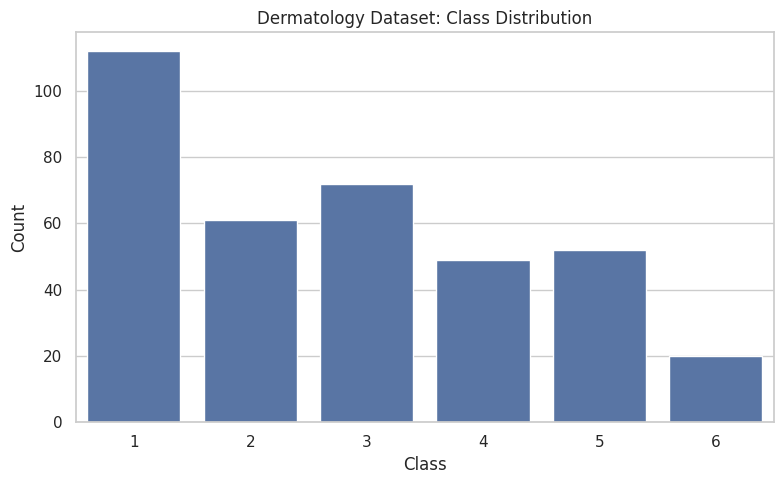

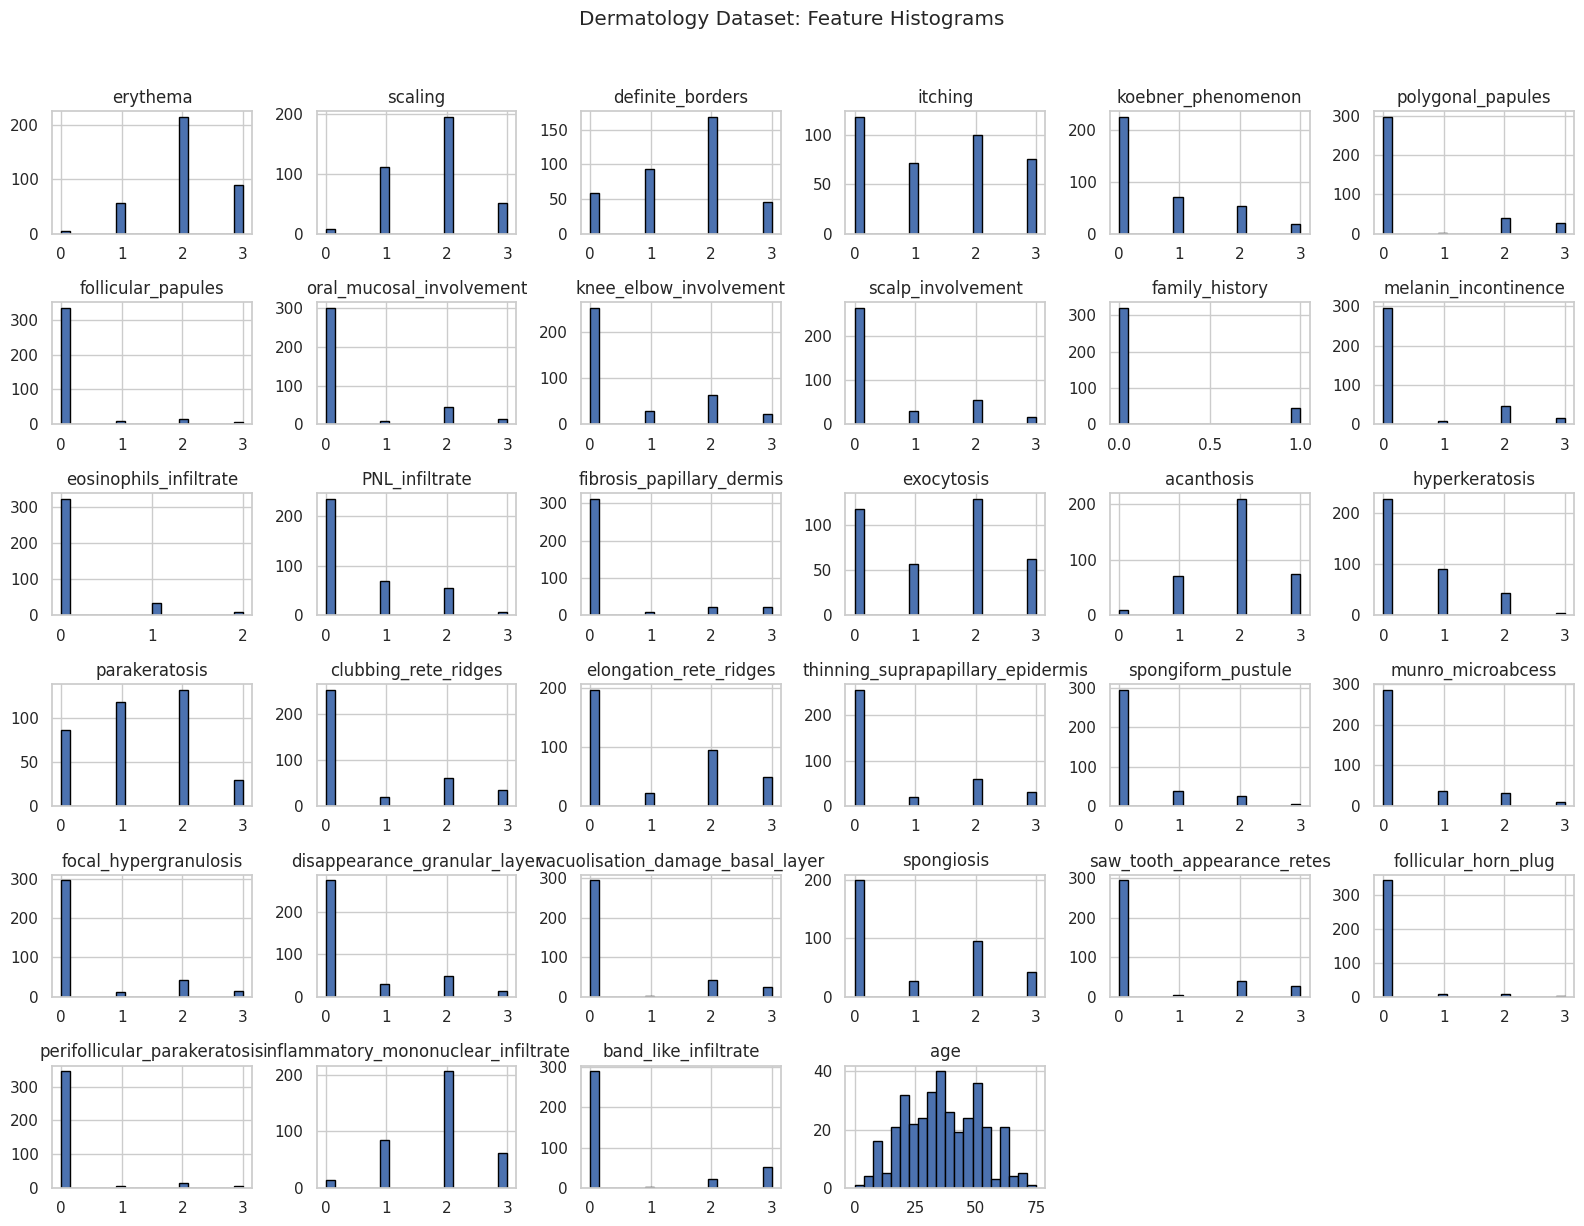

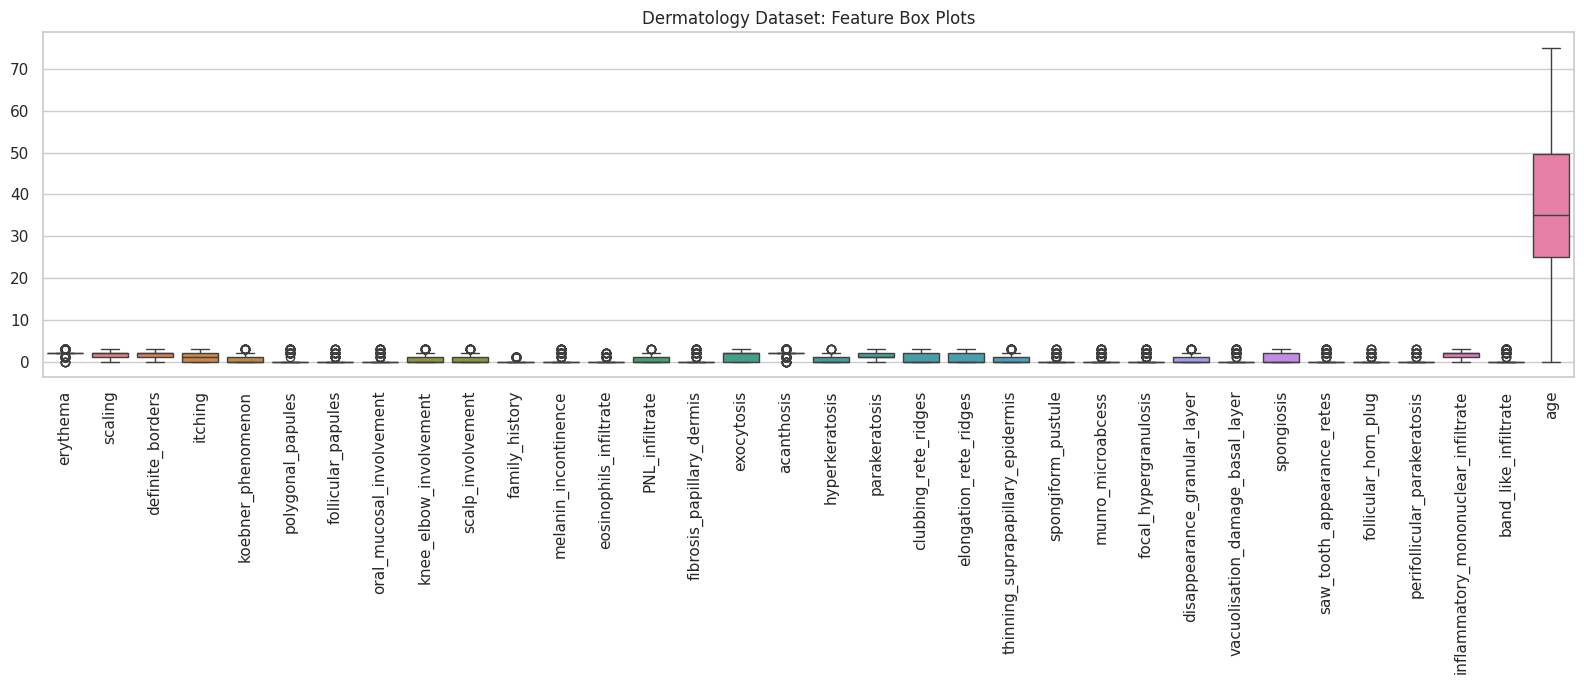

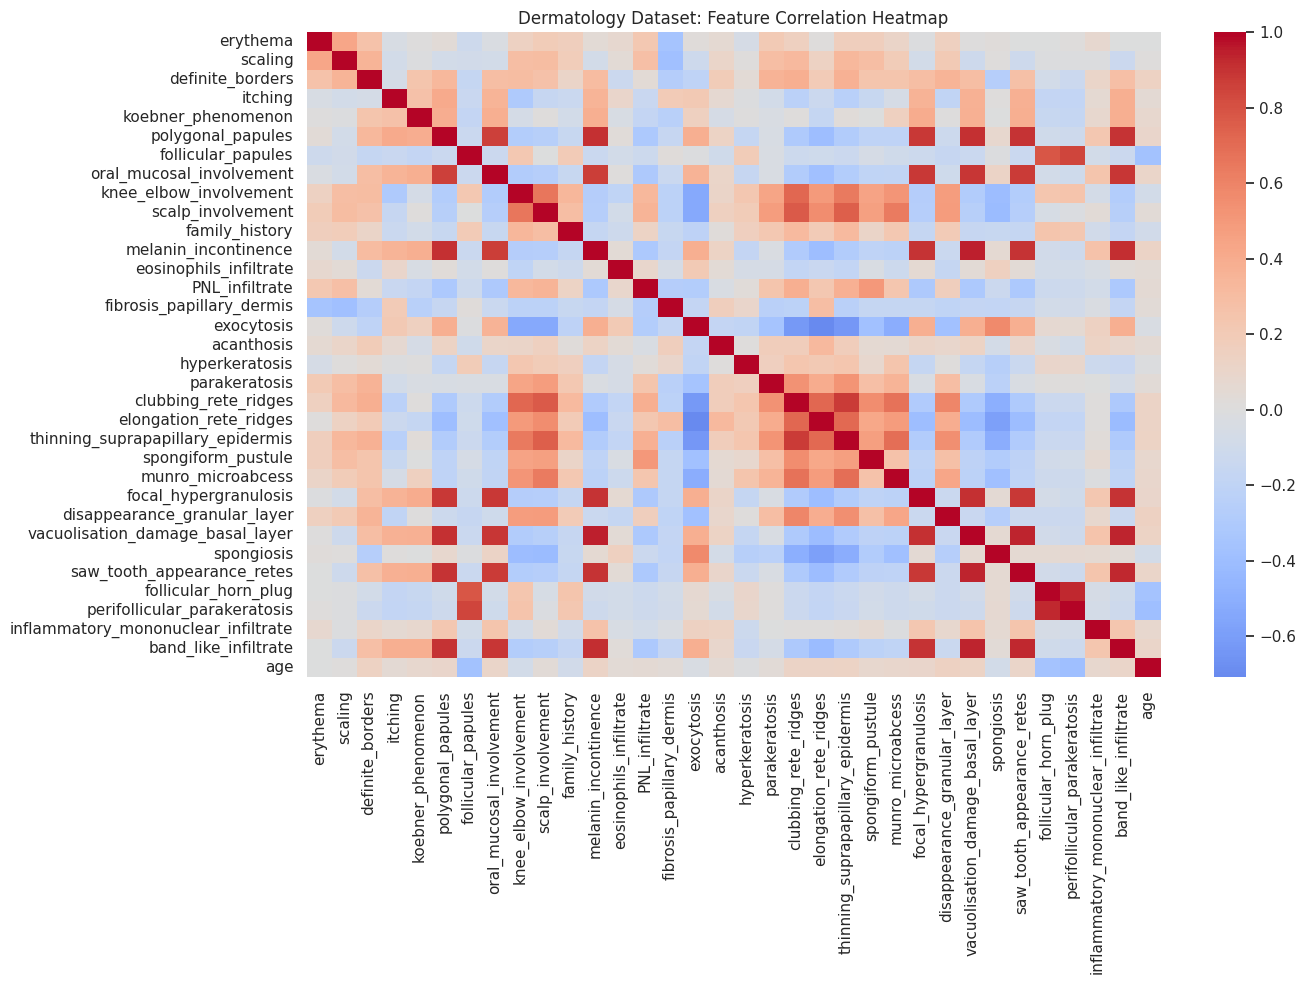


Outliers detected per feature:
 erythema                               151
scaling                                  0
definite_borders                         0
itching                                  0
koebner_phenomenon                      18
polygonal_papules                       69
follicular_papules                      33
oral_mucosal_involvement                67
knee_elbow_involvement                  23
scalp_involvement                       16
family_history                          46
melanin_incontinence                    70
eosinophils_infiltrate                  42
PNL_infiltrate                           7
fibrosis_papillary_dermis               54
exocytosis                               0
acanthosis                             156
hyperkeratosis                           5
parakeratosis                            0
clubbing_rete_ridges                     0
elongation_rete_ridges                   0
thinning_suprapapillary_epidermis       31
spongiform_pustule   

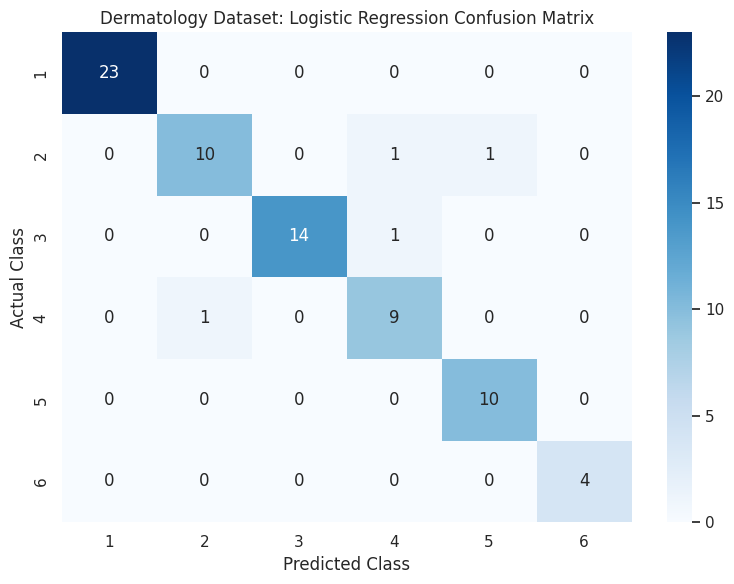

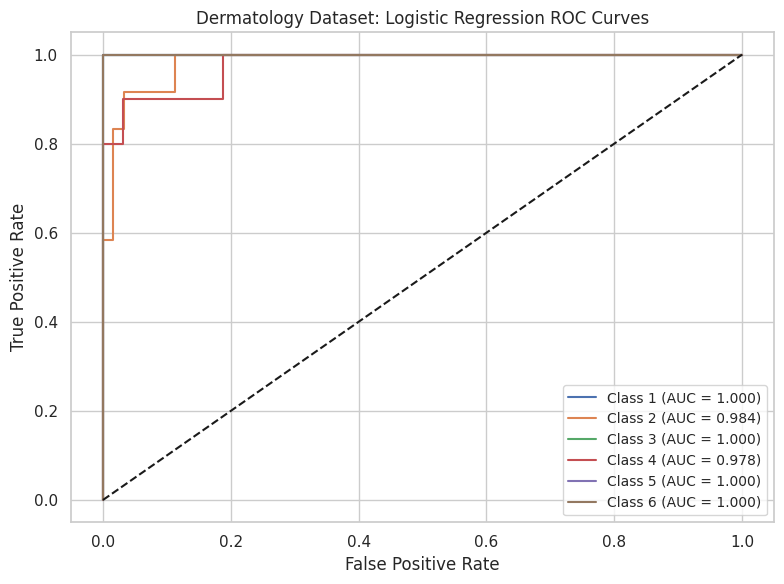


--------------------------------------------------
KNN
--------------------------------------------------
Accuracy: 0.9324
Macro Precision: 0.9294
Macro Recall: 0.9278
Macro F1-score: 0.9246
Macro ROC-AUC: 0.967

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.89      0.67      0.76        12
           3       0.94      1.00      0.97        15
           4       0.75      0.90      0.82        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.93        74
   macro avg       0.93      0.93      0.92        74
weighted avg       0.94      0.93      0.93        74



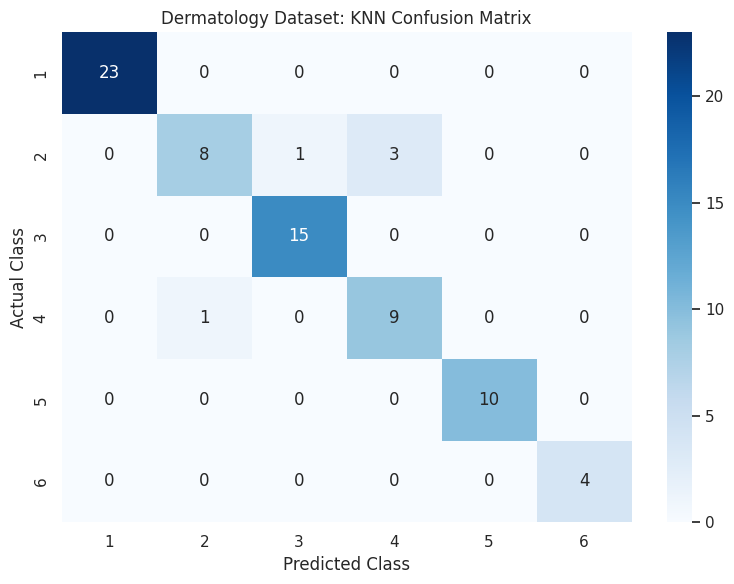

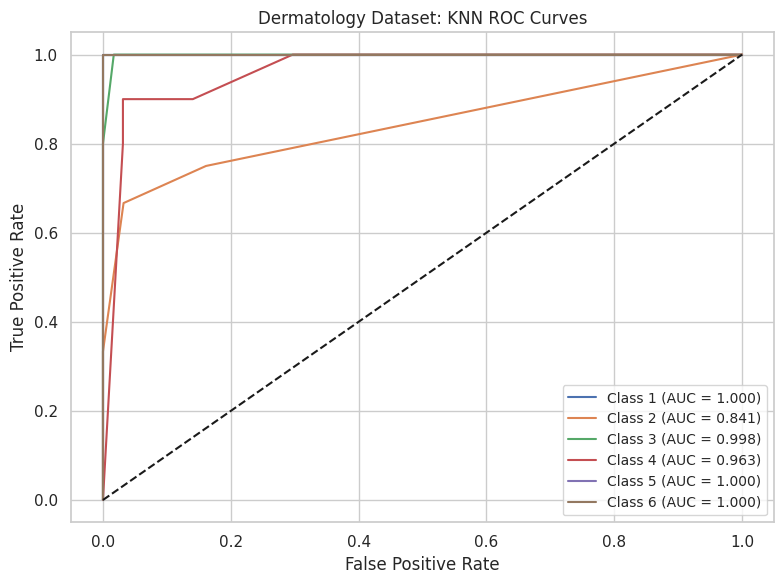


--------------------------------------------------
Random Forest
--------------------------------------------------
Accuracy: 0.8919
Macro Precision: 0.8833
Macro Recall: 0.8889
Macro F1-score: 0.8841
Macro ROC-AUC: 0.9918

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.67      0.67      0.67        12
           3       1.00      0.87      0.93        15
           4       0.80      0.80      0.80        10
           5       0.83      1.00      0.91        10
           6       1.00      1.00      1.00         4

    accuracy                           0.89        74
   macro avg       0.88      0.89      0.88        74
weighted avg       0.90      0.89      0.89        74



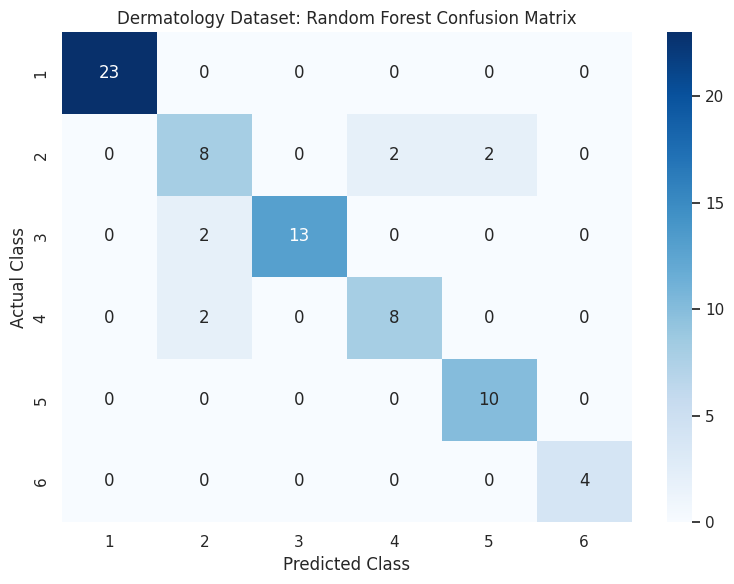

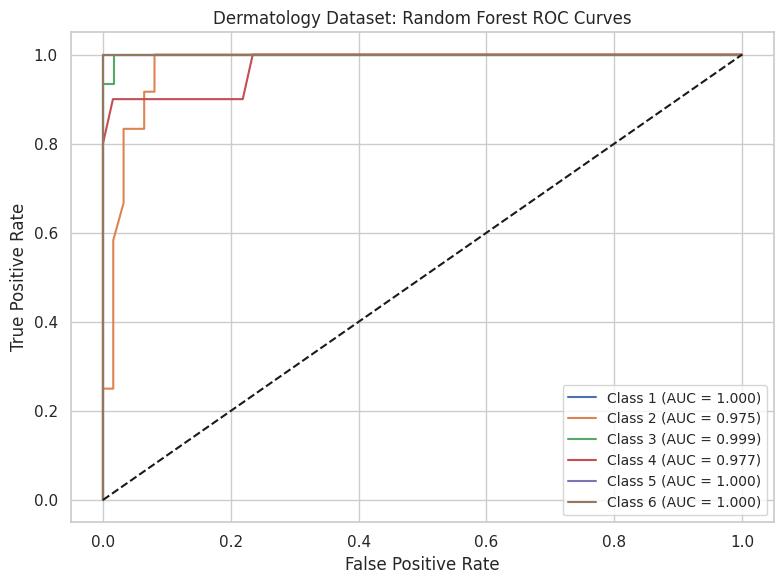


--------------------------------------------------
SVM
--------------------------------------------------
Accuracy: 0.9459
Macro Precision: 0.9417
Macro Recall: 0.9417
Macro F1-score: 0.9394
Macro ROC-AUC: 0.9934

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.90      0.75      0.82        12
           3       1.00      1.00      1.00        15
           4       0.75      0.90      0.82        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.95        74
   macro avg       0.94      0.94      0.94        74
weighted avg       0.95      0.95      0.95        74



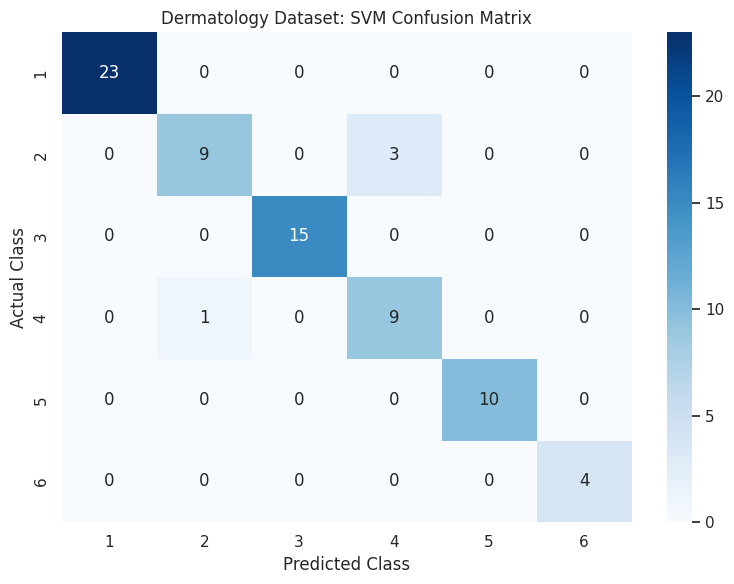

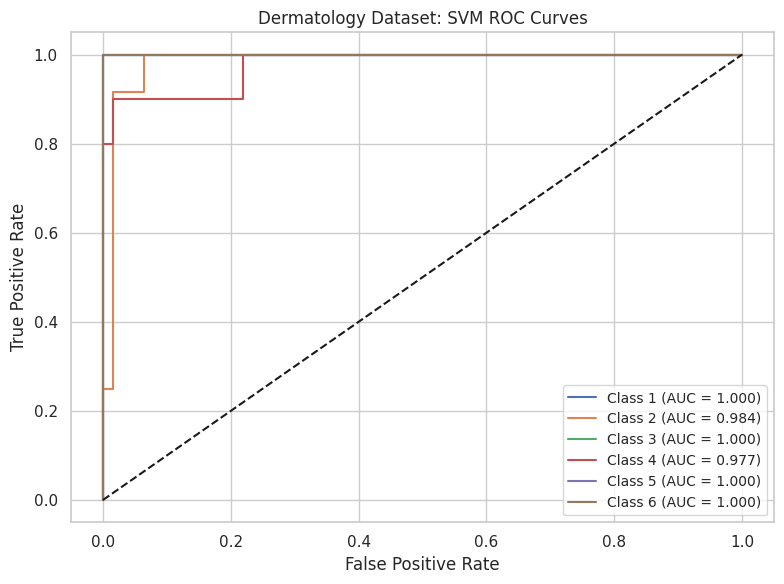


--------------------------------------------------
Decision Tree
--------------------------------------------------
Accuracy: 0.8784
Macro Precision: 0.8517
Macro Recall: 0.8722
Macro F1-score: 0.8568
Macro ROC-AUC: 0.9243

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.71      0.83      0.77        12
           3       1.00      0.80      0.89        15
           4       0.78      0.70      0.74        10
           5       0.82      0.90      0.86        10
           6       0.80      1.00      0.89         4

    accuracy                           0.88        74
   macro avg       0.85      0.87      0.86        74
weighted avg       0.89      0.88      0.88        74



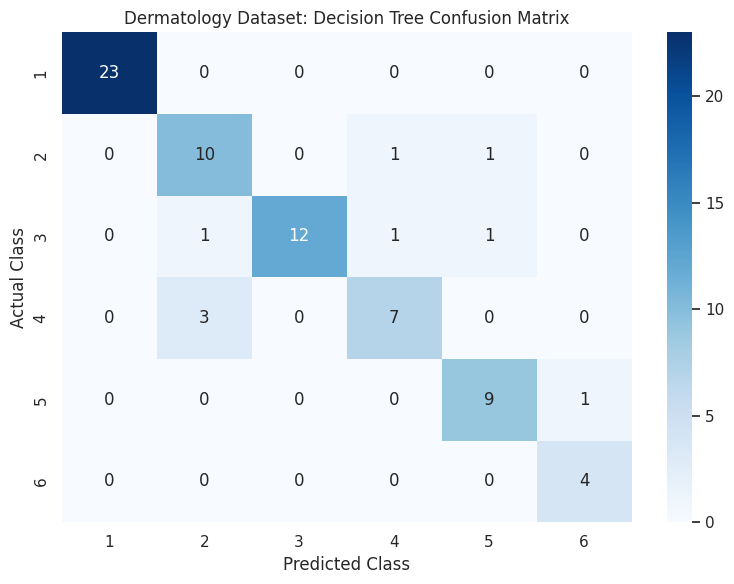

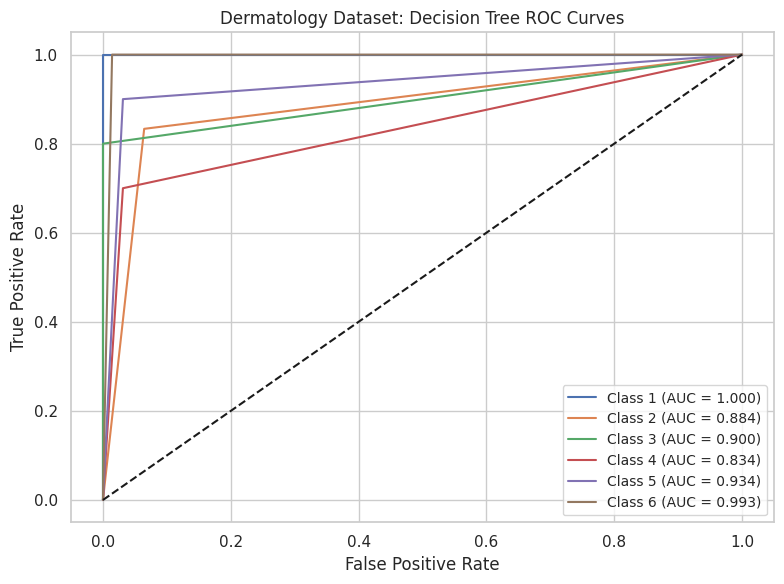


MODEL COMPARISON
              Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  ROC-AUC (Macro)
Logistic Regression    0.9459             0.9394          0.9444            0.9408           0.9937
                KNN    0.9324             0.9294          0.9278            0.9246           0.9670
      Random Forest    0.8919             0.8833          0.8889            0.8841           0.9918
                SVM    0.9459             0.9417          0.9417            0.9394           0.9934
      Decision Tree    0.8784             0.8517          0.8722            0.8568           0.9243


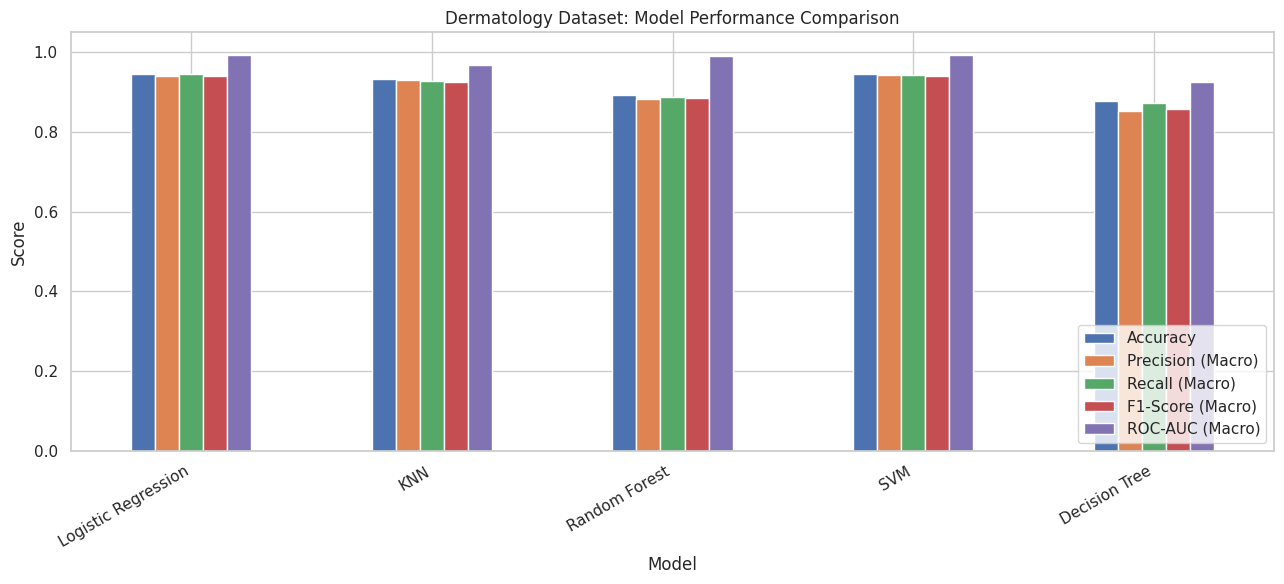


CLASS IMBALANCE ANALYSIS
   Count  Percentage
1    112       30.60
2     61       16.67
3     72       19.67
4     49       13.39
5     52       14.21
6     20        5.46
The dataset has an uneven class distribution. A model may perform better on frequent classes and worse on rare classes. Macro precision, recall and F1-score help evaluate all classes more evenly.


In [31]:
dermatology_results, dermatology_models = run_classification(
    dermatology,
    "Dermatology Dataset"
)


Vertebral Dataset

Number of samples: 310
Number of features: 6
Classes: ['DH', 'NO', 'SL']

Missing values per feature:
 pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
dtype: int64

Class distribution:
 DH     60
NO    100
SL    150
Name: count, dtype: int64


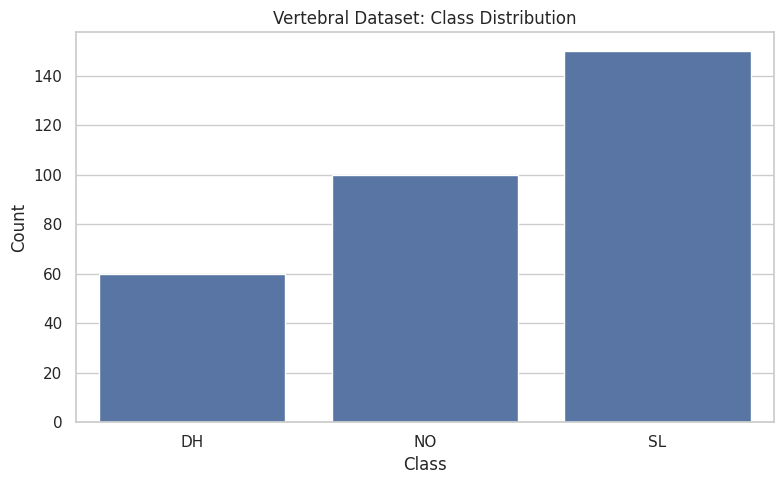

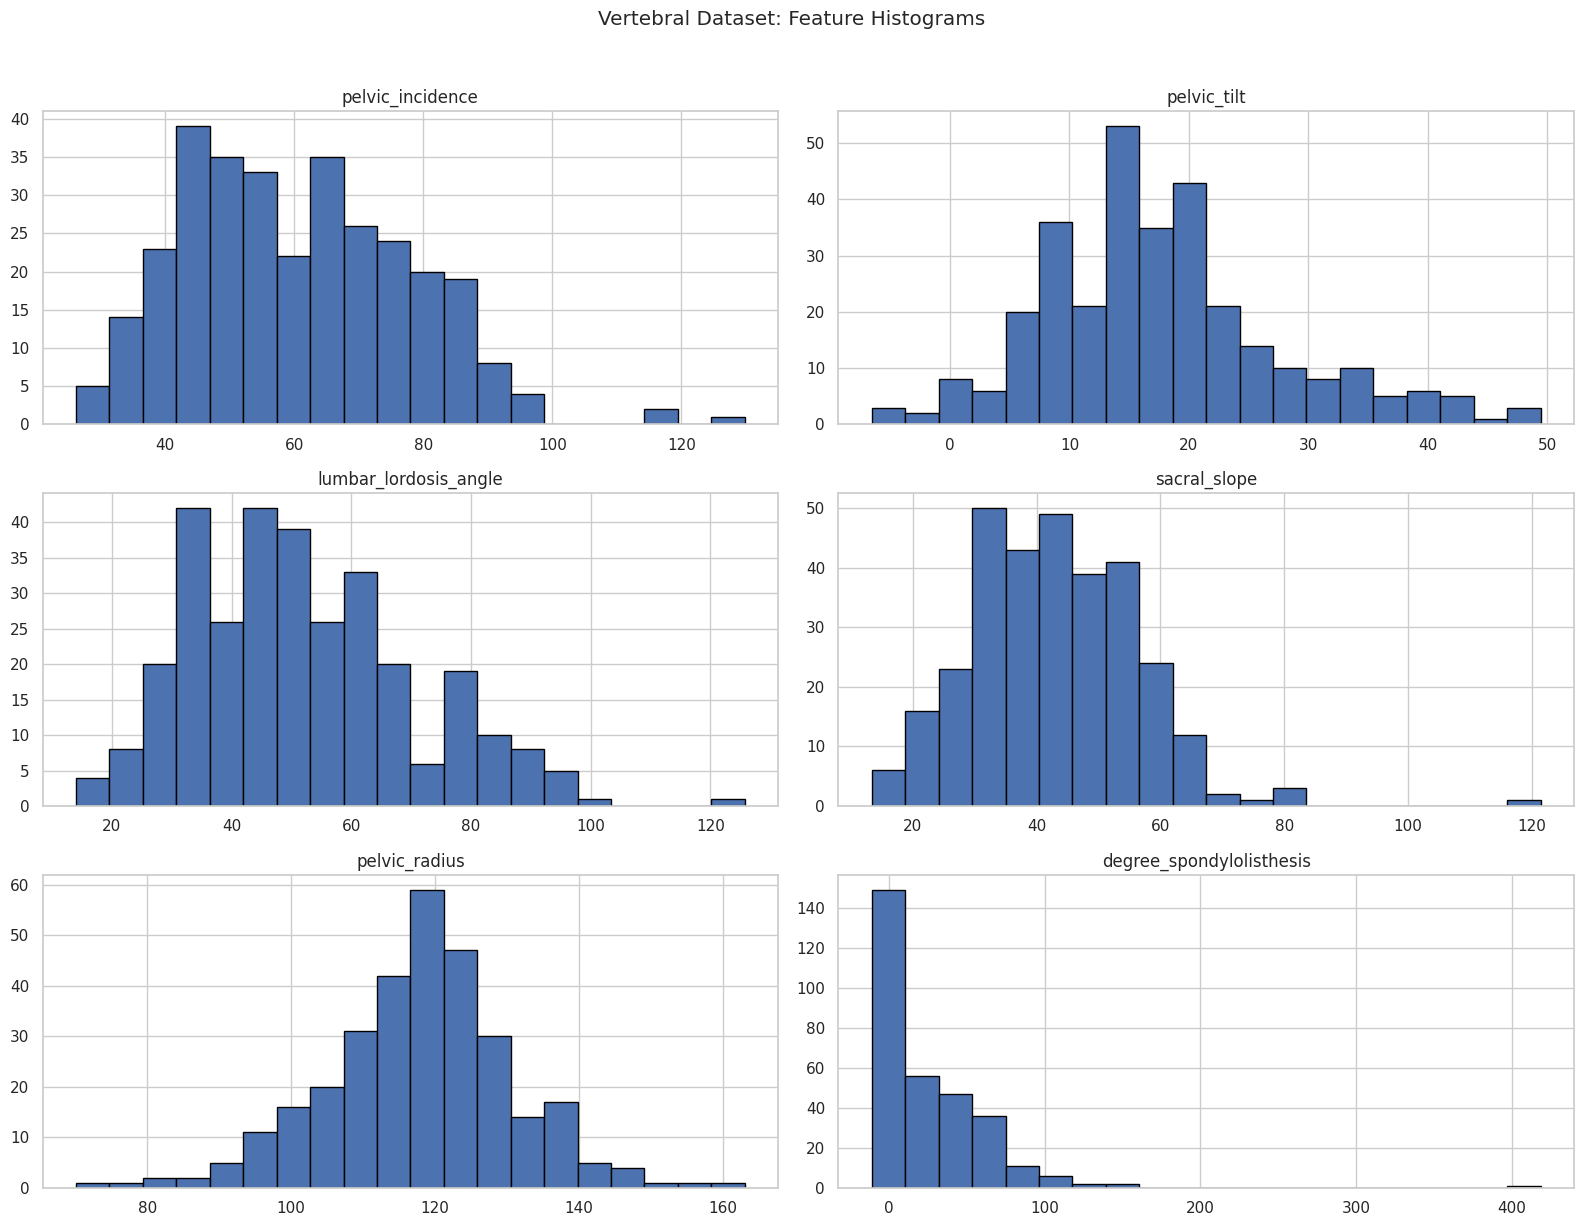

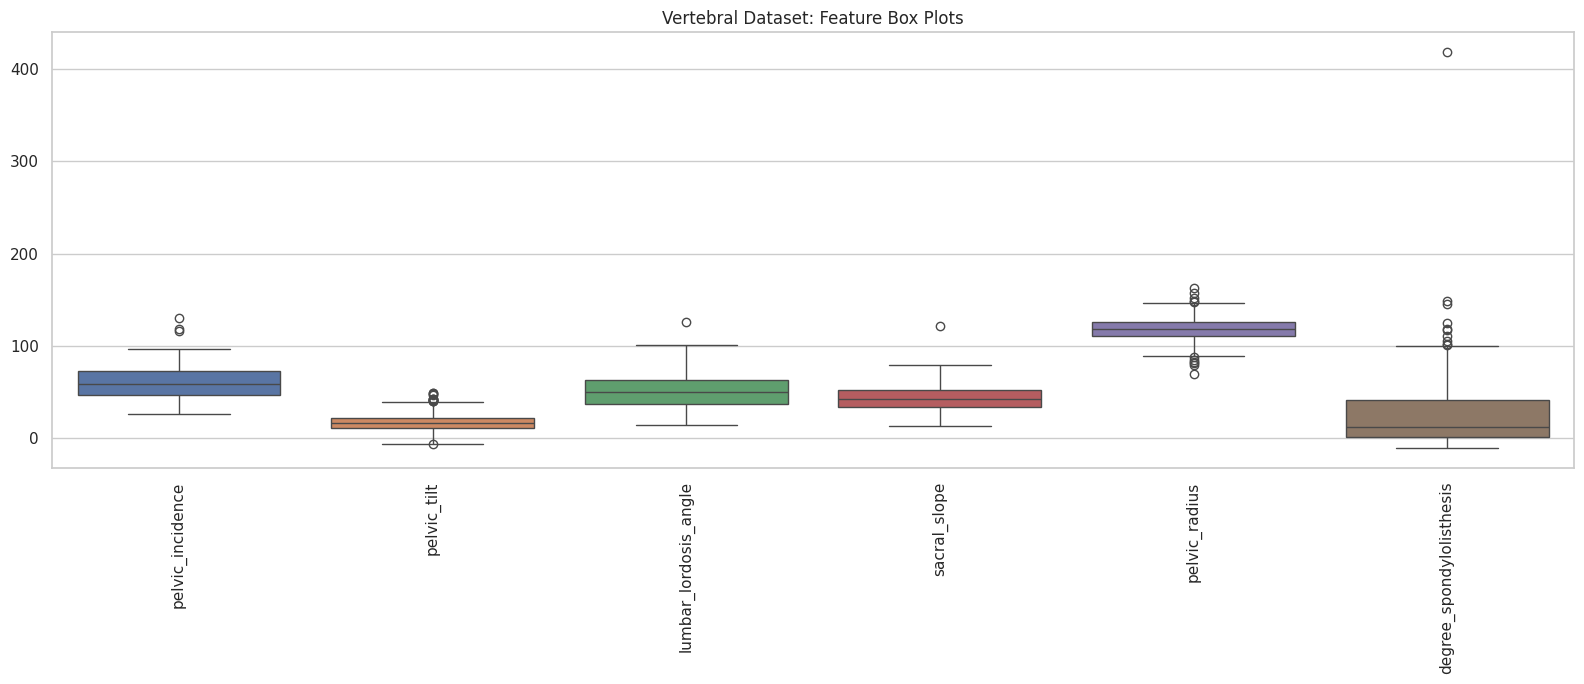

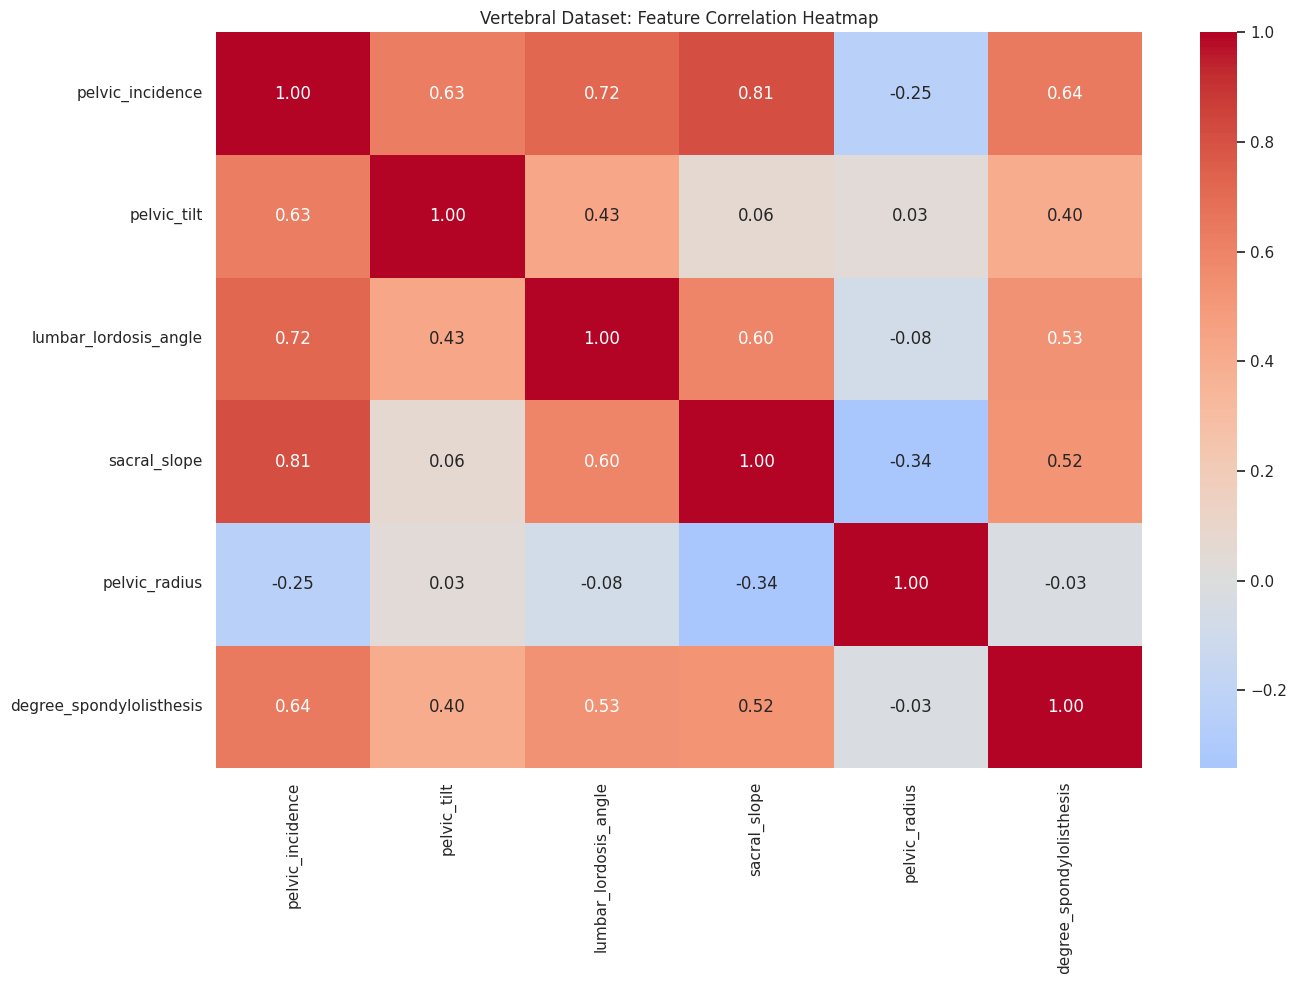


Outliers detected per feature:
 pelvic_incidence             3
pelvic_tilt                 13
lumbar_lordosis_angle        1
sacral_slope                 1
pelvic_radius               11
degree_spondylolisthesis    10
dtype: int64

--------------------------------------------------
Logistic Regression
--------------------------------------------------
Accuracy: 0.8548
Macro Precision: 0.8187
Macro Recall: 0.8389
Macro F1-score: 0.8252
Macro ROC-AUC: 0.9446

Classification Report:
              precision    recall  f1-score   support

          DH       0.67      0.83      0.74        12
          NO       0.79      0.75      0.77        20
          SL       1.00      0.93      0.97        30

    accuracy                           0.85        62
   macro avg       0.82      0.84      0.83        62
weighted avg       0.87      0.85      0.86        62



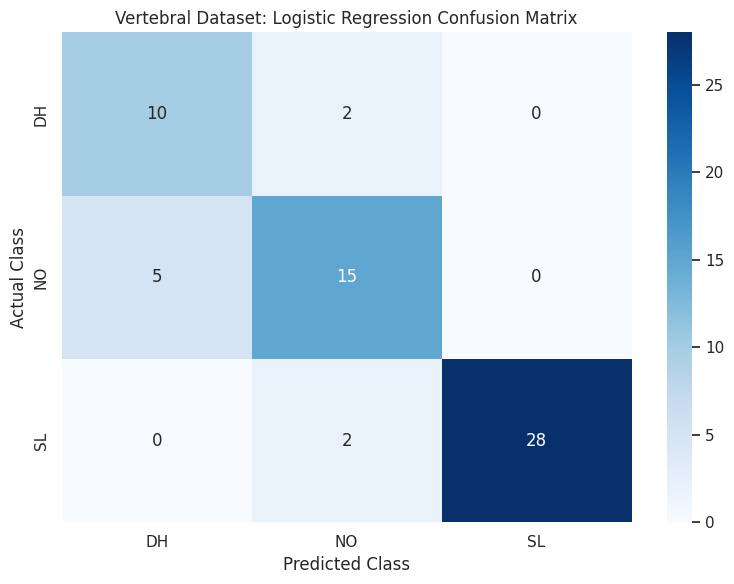

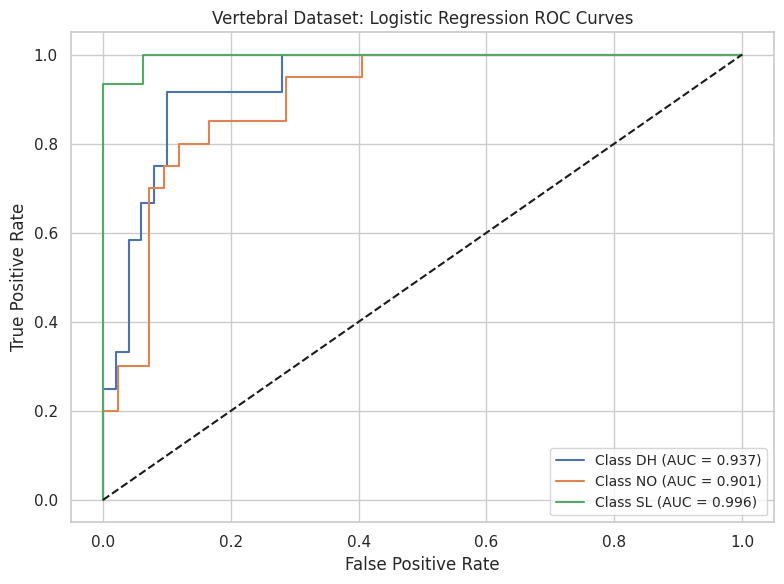


--------------------------------------------------
KNN
--------------------------------------------------
Accuracy: 0.7903
Macro Precision: 0.7774
Macro Recall: 0.7833
Macro F1-score: 0.7733
Macro ROC-AUC: 0.8998

Classification Report:
              precision    recall  f1-score   support

          DH       0.69      0.75      0.72        12
          NO       0.64      0.80      0.71        20
          SL       1.00      0.80      0.89        30

    accuracy                           0.79        62
   macro avg       0.78      0.78      0.77        62
weighted avg       0.82      0.79      0.80        62



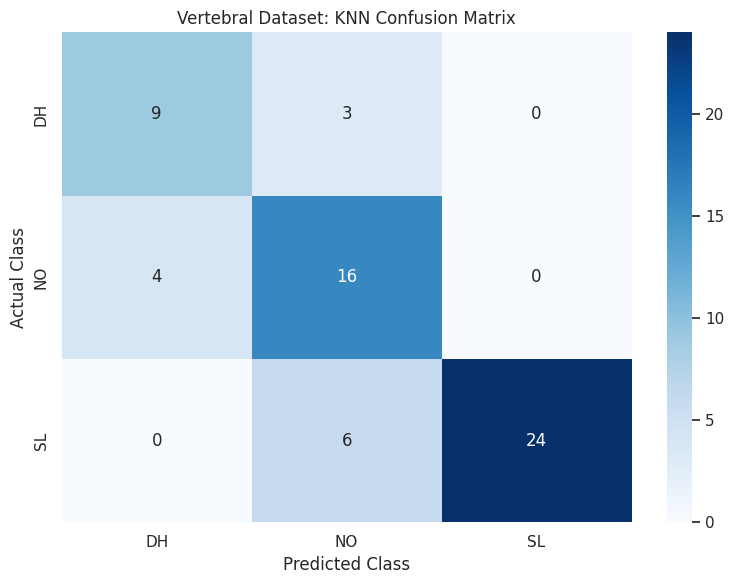

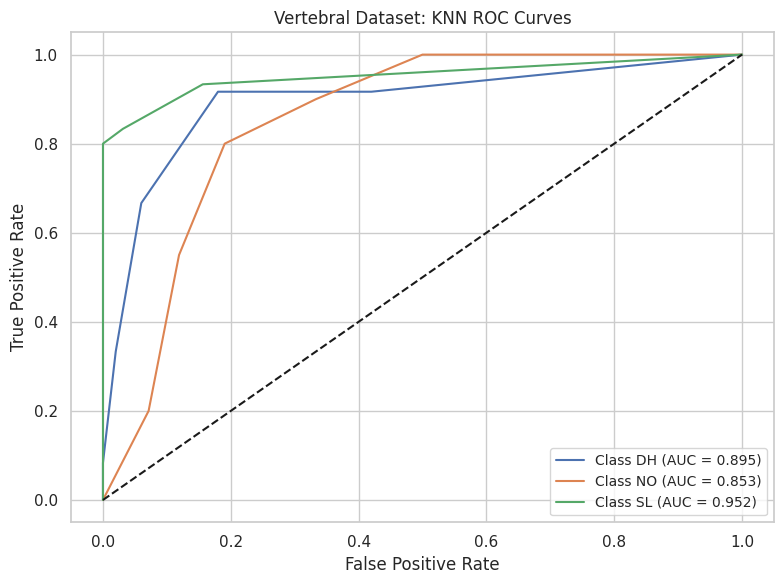


--------------------------------------------------
Random Forest
--------------------------------------------------
Accuracy: 0.8548
Macro Precision: 0.8186
Macro Recall: 0.8111
Macro F1-score: 0.8143
Macro ROC-AUC: 0.9492

Classification Report:
              precision    recall  f1-score   support

          DH       0.73      0.67      0.70        12
          NO       0.76      0.80      0.78        20
          SL       0.97      0.97      0.97        30

    accuracy                           0.85        62
   macro avg       0.82      0.81      0.81        62
weighted avg       0.85      0.85      0.85        62



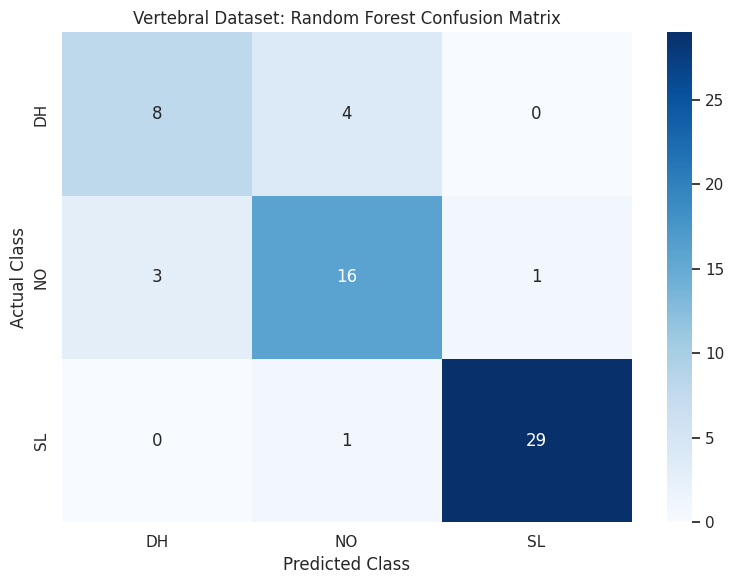

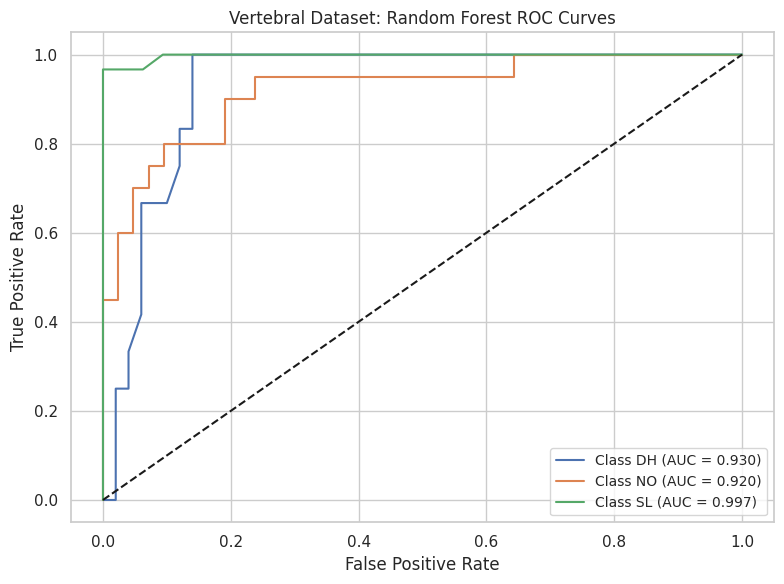


--------------------------------------------------
SVM
--------------------------------------------------
Accuracy: 0.8065
Macro Precision: 0.7828
Macro Recall: 0.8056
Macro F1-score: 0.788
Macro ROC-AUC: 0.9421

Classification Report:
              precision    recall  f1-score   support

          DH       0.67      0.83      0.74        12
          NO       0.68      0.75      0.71        20
          SL       1.00      0.83      0.91        30

    accuracy                           0.81        62
   macro avg       0.78      0.81      0.79        62
weighted avg       0.83      0.81      0.81        62



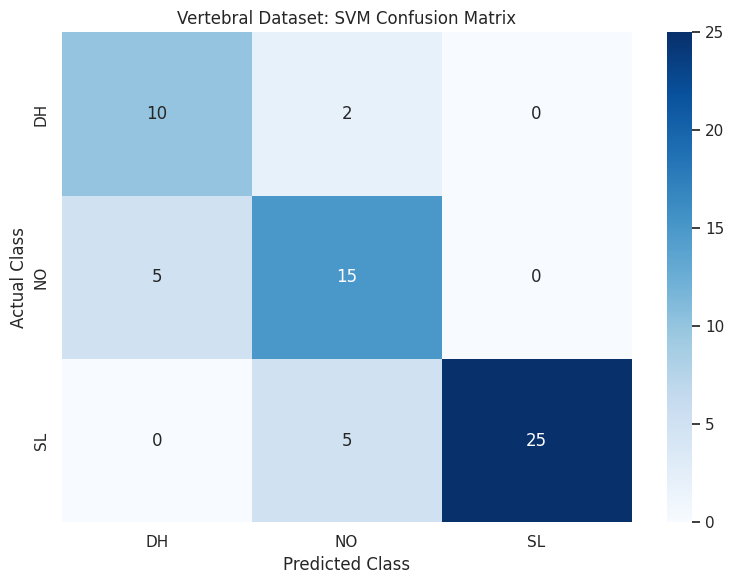

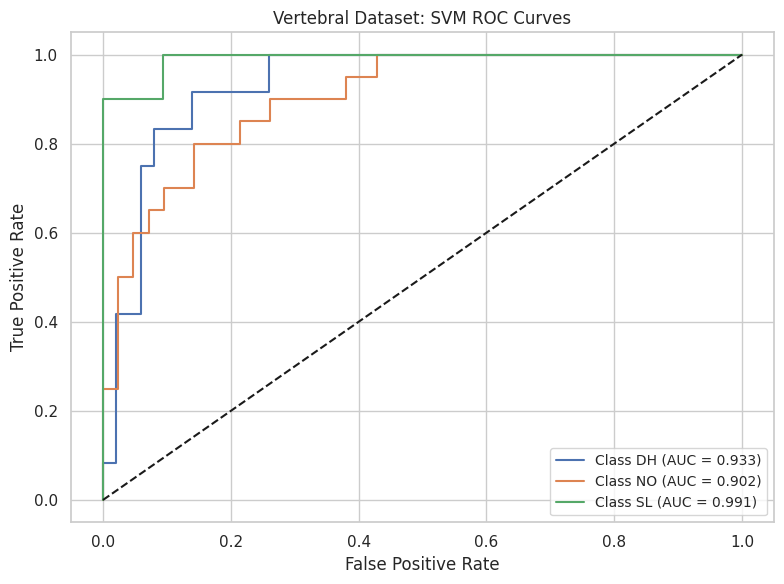


--------------------------------------------------
Decision Tree
--------------------------------------------------
Accuracy: 0.7419
Macro Precision: 0.6757
Macro Recall: 0.6778
Macro F1-score: 0.6764
Macro ROC-AUC: 0.7786

Classification Report:
              precision    recall  f1-score   support

          DH       0.46      0.50      0.48        12
          NO       0.60      0.60      0.60        20
          SL       0.97      0.93      0.95        30

    accuracy                           0.74        62
   macro avg       0.68      0.68      0.68        62
weighted avg       0.75      0.74      0.75        62



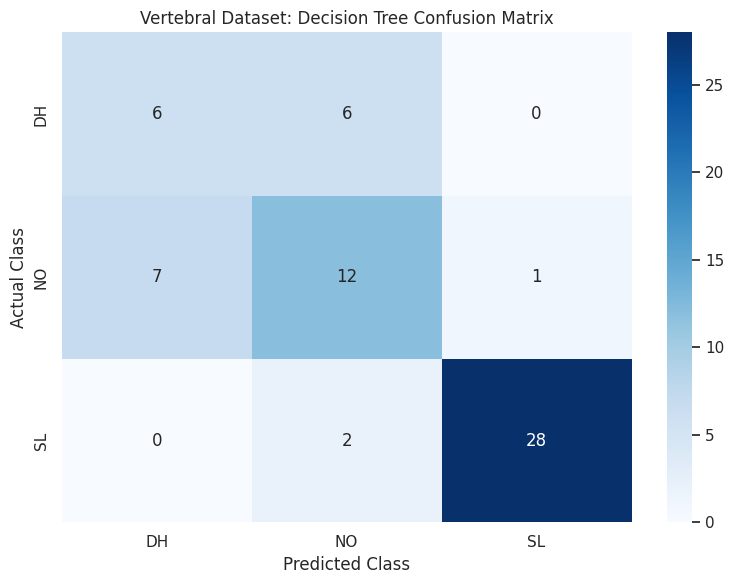

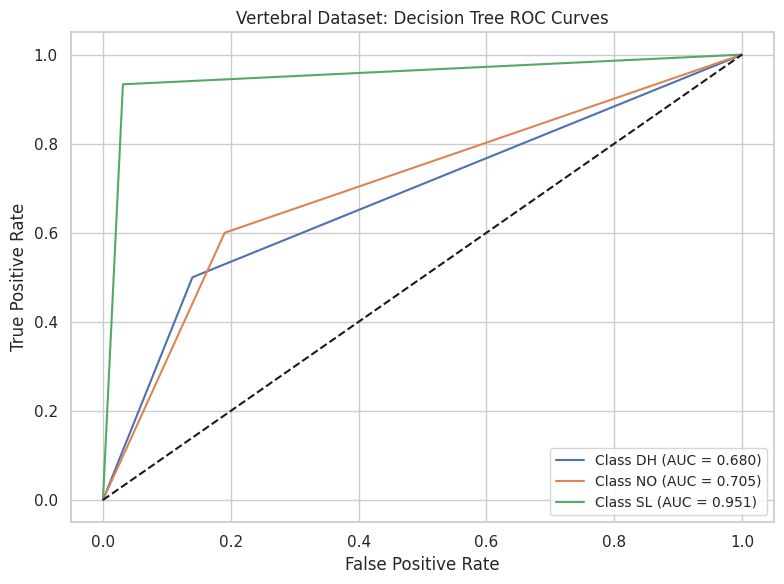


MODEL COMPARISON
              Model  Accuracy  Precision (Macro)  Recall (Macro)  F1-Score (Macro)  ROC-AUC (Macro)
Logistic Regression    0.8548             0.8187          0.8389            0.8252           0.9446
                KNN    0.7903             0.7774          0.7833            0.7733           0.8998
      Random Forest    0.8548             0.8186          0.8111            0.8143           0.9492
                SVM    0.8065             0.7828          0.8056            0.7880           0.9421
      Decision Tree    0.7419             0.6757          0.6778            0.6764           0.7786


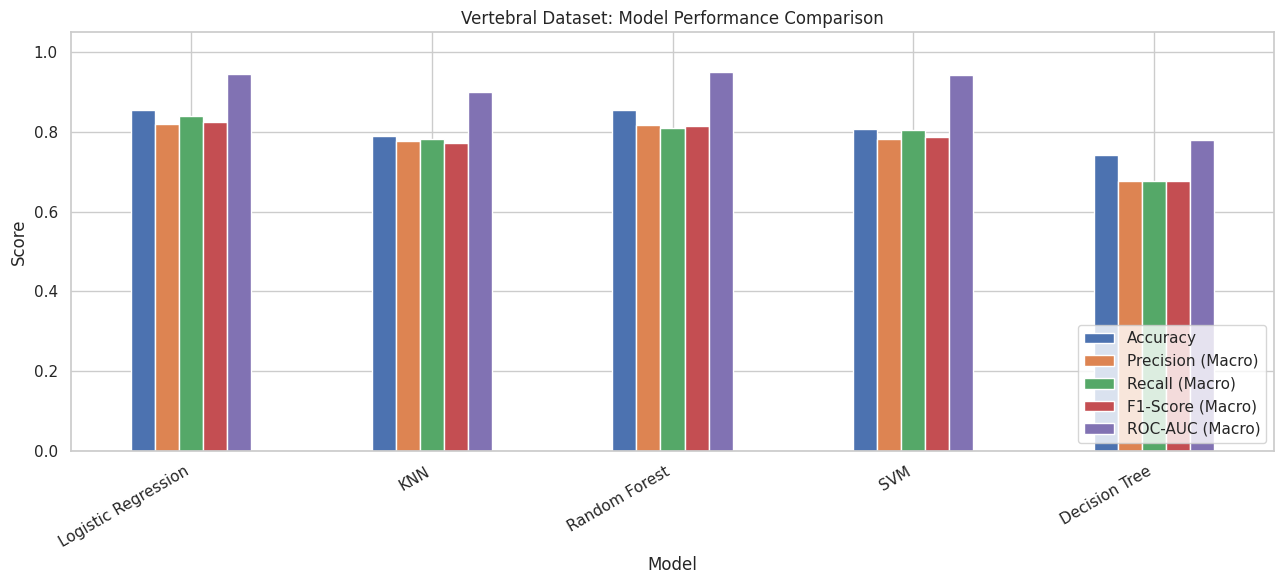


CLASS IMBALANCE ANALYSIS
    Count  Percentage
DH     60       19.35
NO    100       32.26
SL    150       48.39
The dataset has an uneven class distribution. A model may perform better on frequent classes and worse on rare classes. Macro precision, recall and F1-score help evaluate all classes more evenly.


In [32]:
vertebral_results, vertebral_models = run_classification(
    vertebral,
    "Vertebral Dataset"
)